# Czech Bank Scoring Project
##### Выполнил: Петрович Андрей, студент НИУ ВШЭ ОП "Экономика и анализ данных"
##### В этом ноутбуке будет представлена визуализация признаков и  результатов работы полученной модели `(../models/model.joblib)`


##### Импортируем нужные библиотеки: 

In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

##### Данные о модели логистической регрессии, полученные из `01_model.ipynb`

In [2]:
model_info = joblib.load(filename='../models/model.joblib')
print("Известны данные:",*model_info.keys(), sep = " | ")
model = model_info['model']
X_test = model_info['X_test']
f_names = model_info['feature_names']
y_test = model_info['y_test']

Известны данные: | model | X_test | y_test | feature_names


##### Импортируем csv файл с признаками:

In [3]:
df = pd.read_csv('../data/processed/features.csv', index_col='loan_id')
X = df.drop(columns=['bad_loan'])
y = df['bad_loan']

## Блок 1: 

- #### Баланс классов

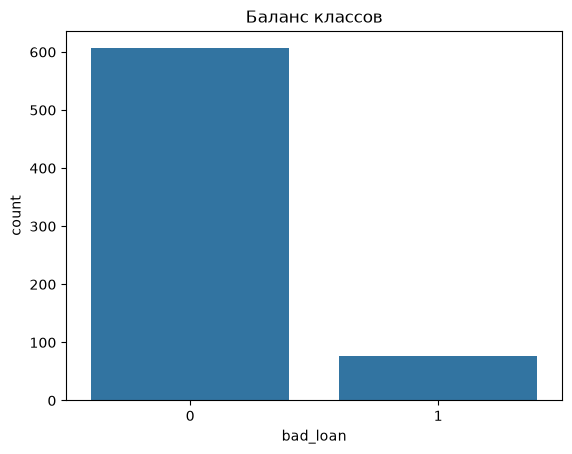

In [4]:
sns.countplot(data = df, x = 'bad_loan')
plt.title("Баланс классов")
plt.savefig('../reports/figures/01_class_balance.png', dpi=150, bbox_inches='tight')
plt.show()

- #### Доля некредитоспособных по `n_negative_balance`

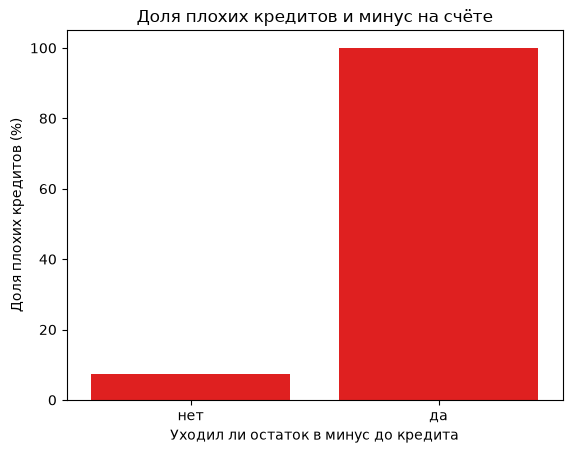

In [5]:
neg = (df['n_negative_balance'] > 0).map({False: 'нет', True: 'да'})
sns.barplot(x=neg, y=df['bad_loan']*100, color='red', errorbar=None, order=['нет', 'да'])
plt.title('Доля плохих кредитов и минус на счёте')
plt.xlabel('Уходил ли остаток в минус до кредита')
plt.ylabel('Доля плохих кредитов (%)')
plt.savefig('../reports/figures/02_negative_balance.png', dpi=150, bbox_inches='tight')
plt.show()

- #### Распределение ключевых признаков у хороших и плохих кредитов

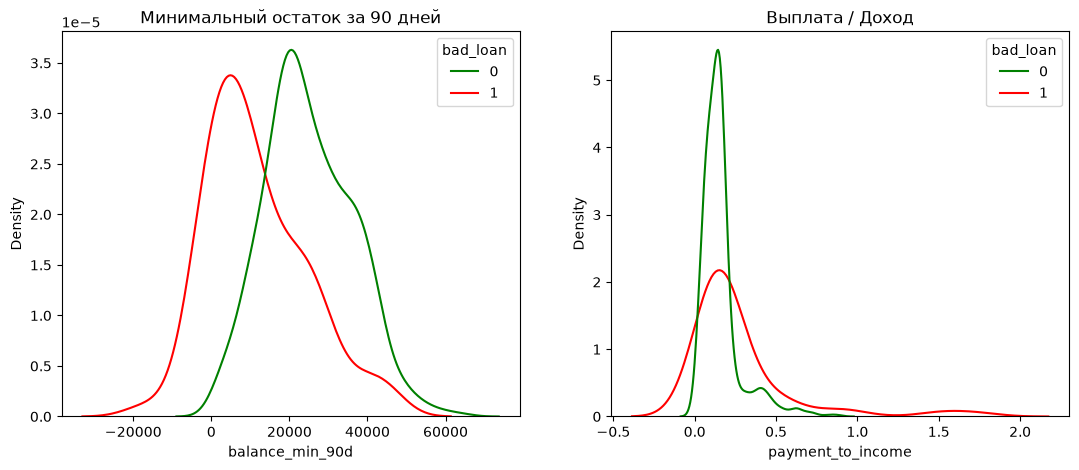

In [6]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(13, 5))
sns.kdeplot(data=df, x='balance_min_90d', hue='bad_loan', common_norm=False, palette=['green', 'red'], ax=axes[0])
sns.kdeplot(data=df, x='payment_to_income', hue='bad_loan', common_norm=False, palette=['green', 'red'], ax=axes[1])
axes[0].set_title('Минимальный остаток за 90 дней')
axes[1].set_title('Выплата / Доход')
plt.savefig('../reports/figures/03_key_features_kde.png', dpi=150, bbox_inches='tight')
plt.show()

- #### Корреляции признаков

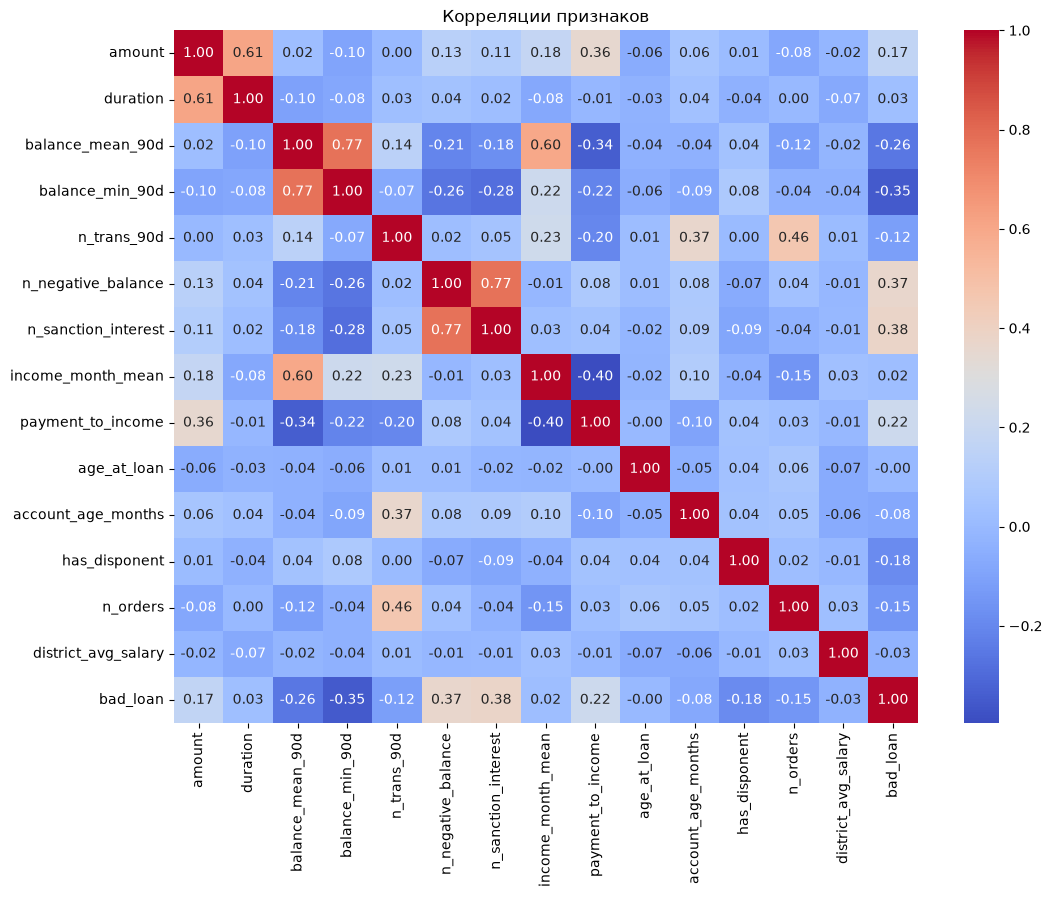

In [7]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap = 'coolwarm')
plt.title('Корреляции признаков')
plt.savefig('../reports/figures/04_correlations.png', dpi=150, bbox_inches='tight')
plt.show()

## Блок 2: Результаты модели

- #### Коэффициенты модели: что повышает и понижает риск

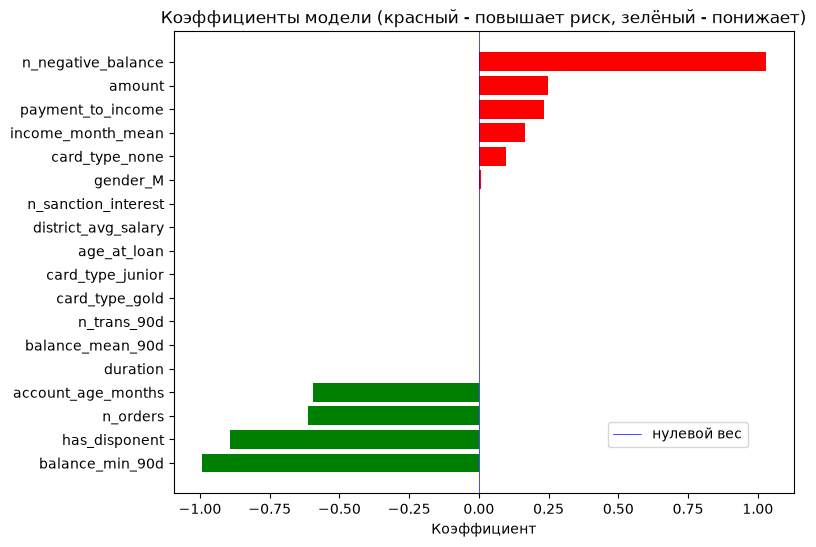

In [8]:
coefs = pd.Series(model.coef_[0], index=f_names).sort_values()
plt.figure(figsize=(8, 6))
plt.barh(coefs.index, coefs, color=['red' if c > 0 else 'green' for c in coefs])
plt.title('Коэффициенты модели (красный - повышает риск, зелёный - понижает)')
plt.xlabel('Коэффициент')
plt.axvline(color = 'blue', linewidth = 0.5, label = 'нулевой вес')
plt.legend(loc = (0.7, 0.1))
plt.savefig('../reports/figures/05_coeffs_importances.png', dpi=150, bbox_inches='tight')
plt.show()

- #### ROC-кривая на тестовой выборке

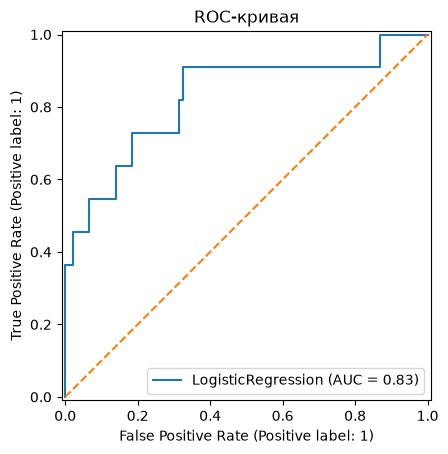

In [9]:
RocCurveDisplay.from_estimator(model, X_test, y_test)
plt.plot([0, 1], [0, 1], '--')
plt.title('ROC-кривая')
plt.savefig('../reports/figures/06_roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()

- #### Матрица ошибок (порог 0.5)

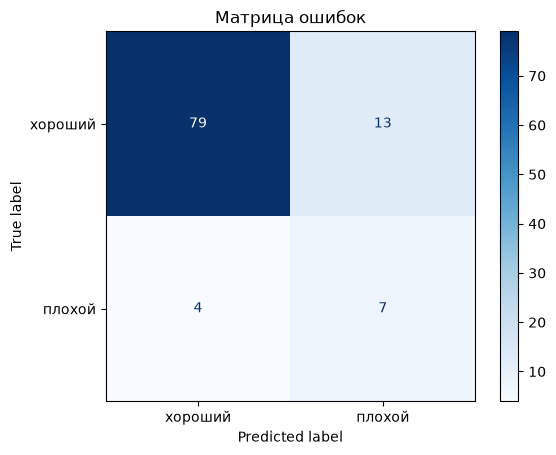

In [10]:
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=['хороший', 'плохой'], cmap='Blues')
plt.title('Матрица ошибок')
plt.savefig('../reports/figures/07_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

- #### Распределение предсказанных вероятностей дефолта

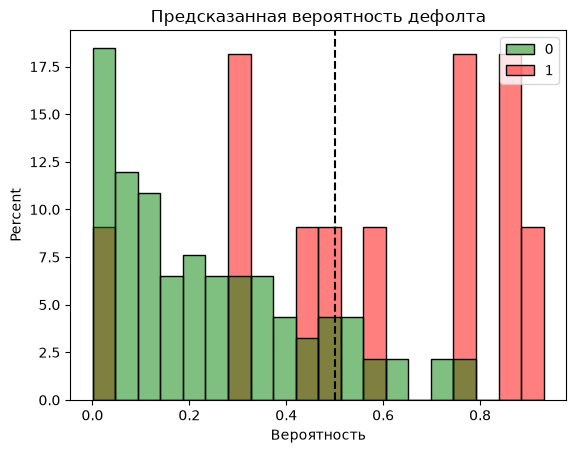

In [11]:
proba = model.predict_proba(X_test)[:, 1]
sns.histplot(x=proba, hue=y_test.values, bins=20, stat='percent', common_norm=False, palette=['green', 'red'])
plt.axvline(0.5, color='black', linestyle='--')
plt.title('Предсказанная вероятность дефолта')
plt.xlabel('Вероятность')
plt.savefig('../reports/figures/08_predicted_proba.png', dpi=150, bbox_inches='tight')
plt.show()

# Спасибо за проявленный интерес !